In [ ]:
!pip install -U typing_extensions
!pip install -U langgraph
!pip install -U langchain
!pip install -U databricks-langchain
!pip install pygame
dbutils.library.restartPython()


In [ ]:
import os
import operator
import subprocess

from typing import Annotated, List

from typing_extensions import TypedDict
from langchain_core.messages import AIMessage, BaseMessage, HumanMessage
from databricks_langchain import ChatDatabricks
from langgraph.checkpoint.memory import MemorySaver
from langgraph.graph import END, START, StateGraph
from langgraph.graph.message import add_messages

# ChatDatabricks uses Databricks workspace credentials (no OpenAI/.env API keys).
# Optional cluster env: DATABRICKS_CHAT_ENDPOINT="<serving-endpoint-name>".

# run_code prefixes execution text so qa_node can read it without a ninth GameState key.
_PA4_RUN_LOG_PREFIX = "__PA4_RUN_LOG__:\n"

MOSAIC_CHAT_ENDPOINT = (
    (os.environ.get("DATABRICKS_CHAT_ENDPOINT") or "").strip()
    or "databricks-meta-llama-3.1-405b-instruct"
)


def make_chat_model(
    model_env: str, temp_env: str, default_model: str, default_temp: float
) -> ChatDatabricks:
    _, _ = model_env, default_model
    temp = float(os.getenv(temp_env, str(default_temp)))
    return ChatDatabricks(endpoint=MOSAIC_CHAT_ENDPOINT, temperature=temp)


print("ChatDatabricks endpoint:", MOSAIC_CHAT_ENDPOINT)


def architect_spec_from_state(state: dict) -> str:
    parts: List[str] = []
    for m in state.get("architect_messages") or []:
        if isinstance(m, AIMessage):
            parts.append(str(m.content))
    return "\n\n".join(parts).strip()



##Task 1: Initializing System Memory and State Management [10 marks]

In [ ]:
class GameState(TypedDict):
    """PA4 Task 1: exact handout keys; add_messages on director/architect."""

    director_messages: Annotated[List[BaseMessage], add_messages]
    architect_messages: Annotated[List[BaseMessage], add_messages]
    engineer_code: str
    qa_feedback: str
    current_actor: str
    iteration: int
    iteration_score: Annotated[List[float], operator.add]
    file_saved: bool



## Task 2: Implement Agent Nodes [40 marks]

### Subtask 2.1: Director and Architect Nodes

In [ ]:
def director_node(state: GameState):
    director_msg = input("Awaiting Director Prompt: ").strip()
    return {
        "director_messages": [
            HumanMessage(
                content=director_msg,
                additional_kwargs={"role": "director"},
            )
        ],
        "current_actor": "director",
    }


def architect_node(state: GameState):
    it = int(state.get("iteration", 0))
    print(f"\n========== ITERATION {it} (architect pass) ==========")

    brief = ""
    for m in reversed(state.get("director_messages") or []):
        if isinstance(m, HumanMessage) and m.additional_kwargs.get("role") == "director":
            brief = str(m.content)
            break

    qa_fb = (state.get("qa_feedback") or "").strip()
    if it > 0 and qa_fb and not qa_fb.startswith(_PA4_RUN_LOG_PREFIX):
        print("[QA feedback from last run]\n", qa_fb, sep="")

    print(
        "Architect: describe pygame requirements for the Dino Runner (PA4: flying + ground obstacles, "
        "jump/duck physics, high score).\n"
        f"Director brief (latest): {brief!r}\n"
    )
    spec = input("Architect requirements (multi-line; end with empty line):\n")
    while True:
        line = input()
        if not line.strip():
            break
        spec += "\n" + line

    spec = spec.strip()
    if not spec and brief:
        spec = brief

    return {
        "architect_messages": [AIMessage(content=f"[Architect spec]\n{spec}")],
        "current_actor": "architect",
    }



### Subtask 2.2: Engineer Node

In [0]:
def engineer_node(state: GameState):
    from langchain_core.messages import SystemMessage

    spec = architect_spec_from_state(state)
    prev_code = (state.get("engineer_code") or "").strip()
    qa_fb = (state.get("qa_feedback") or "").strip()

    sys_prompt = """You implement a runnable Chrome-style DINO RUNNER in one Python file using pygame.
PA4 demo requirements — the game MUST include ALL of:
1) Flying obstacles (e.g. pterodactyl-style) at varying heights.
2) Ground obstacles (e.g. cacti).
3) Jump physics: gravity, landing on ground — not instantaneous teleport.
4) Duck mechanic (mapped to a key such as DOWN or S) and jump (SPACE or UP).
5) Persisted HIGH SCORE across runs (simple local file JSON or plaintext in cwd is OK).

Output rules:
- Return ONLY valid Python inside one markdown fence: ```python ... ```.
- Entry: `if __name__ == "__main__":` runs `main()` / game loop.
- Dependencies: stdlib + pygame only. Handle pygame.QUIT and window close cleanly.
"""

    chunks = [
        "### Architect specification",
        spec or "(none — use QA if empty)",
        "### Prior QA feedback (latest)",
        qa_fb or "(none yet)",
    ]
    if prev_code:
        chunks.extend(
            [
                "### Existing code — revise (keep working parts)",
                prev_code[:120_000],
            ]
        )

    human = HumanMessage(content="\n\n".join(chunks))
    llm = make_chat_model(
        model_env="ENGINEER_MODEL",
        temp_env="ENGINEER_TEMP",
        default_model="",
        default_temp=0.2,
    )
    ai = llm.invoke([SystemMessage(content=sys_prompt), human])
    reply = getattr(ai, "content", str(ai)).strip()

    def extract_py(src: str) -> str:
        fence = "```python"
        if fence in src:
            blob = src.split(fence, 1)[1]
            return blob.split("```", 1)[0].strip()
        if "```" in src:
            return src.split("```", 1)[1].split("```", 1)[0].strip()
        return src.strip()

    new_code = extract_py(reply)
    return {
        "engineer_code": new_code,
        "current_actor": "engineer",
    }


### Subtask 2.3: File I/O and Execution Nodes

In [ ]:
def _runner_filename() -> str:
    roll = (os.getenv("ROLL_NUMBER") or "").strip()
    return f"{roll}_dino_runner.py" if roll else "dino_runner.py"


def file_writer(state: GameState):
    code = (state.get("engineer_code") or "").strip()
    if not code:
        code = "# engineer_code was empty\npass\n"

    filename = _runner_filename()
    path = os.path.abspath(filename)
    with open(path, "w", encoding="utf-8", newline="\n") as f:
        f.write(code)

    snippet = code if len(code) <= 500 else code[:500] + "\n... [truncated for display]"
    print(snippet)
    print(f"\n[File saved: {path}]")
    return {"file_saved": True, "current_actor": "file_writer"}


def run_code(state: GameState):
    import sys

    print("\n===== CODE EXECUTION (human-in-the-loop) =====")
    choice = input("Run the generated game? (y/n): ").strip().lower()

    filename = _runner_filename()
    if choice != "y":
        log = f"[skipped] User chose not to run {filename}."
        return {
            "qa_feedback": _PA4_RUN_LOG_PREFIX + log,
            "current_actor": "execution_manager",
        }

    script = os.path.abspath(filename)
    exe = sys.executable or "python"
    chunks: List[str] = []

    chk = subprocess.run(
        [exe, "-m", "py_compile", script],
        capture_output=True,
        text=True,
        timeout=120,
        cwd=os.path.dirname(script) or ".",
    )
    chunks.append(f"=== python -m py_compile {filename} (exit {chk.returncode}) ===")
    if chk.stdout.strip():
        chunks.append(chk.stdout.rstrip())
    if chk.stderr.strip():
        chunks.append(chk.stderr.rstrip())
    if chk.returncode != 0:
        return {
            "qa_feedback": _PA4_RUN_LOG_PREFIX + "\n".join(chunks),
            "current_actor": "execution_manager",
        }

    try:
        proc = subprocess.run(
            [exe, script],
            capture_output=True,
            text=True,
            timeout=30,
            cwd=os.path.dirname(script) or ".",
        )
        chunks.append(f"=== python {filename} (exit {proc.returncode}) ===")
        if proc.stdout.strip():
            chunks.append(proc.stdout.rstrip())
        if proc.stderr.strip():
            chunks.append(proc.stderr.rstrip())
    except subprocess.TimeoutExpired as exc:
        chunks.append(
            f"=== python {filename} (stopped after 30s timeout — pygame may not exit headless) ==="
        )
        if exc.stdout:
            chunks.append(exc.stdout.strip())
        if exc.stderr:
            chunks.append(exc.stderr.strip())

    return {
        "qa_feedback": _PA4_RUN_LOG_PREFIX + "\n".join(chunks),
        "current_actor": "execution_manager",
    }



### Subtask 2.4: QA and Scorer Nodes

In [ ]:
def qa_node(state: GameState):
    from langchain_core.messages import SystemMessage

    raw_fb = (state.get("qa_feedback") or "").strip()
    if raw_fb.startswith(_PA4_RUN_LOG_PREFIX):
        run_out = raw_fb[len(_PA4_RUN_LOG_PREFIX) :].strip()
    else:
        run_out = ""

    design = architect_spec_from_state(state).strip()
    engineer_code = (state.get("engineer_code") or "").strip()

    sys_prompt = """You are QA for PA4 pygame Dino Runner (single module).
Produce a numbered review covering:
1) Specification vs PA4 game requirements (flying foes, ground obstacles, jump gravity, duck, high-score persistence).
2) Code quality — pygame lifecycle, events, timestep.
3) What execution logs show (compile, stderr, timeouts, skips).

End with actionable \"Suggested fixes\" bullets."""

    body = f"""## design (architect_messages)
{design[:25_000]}

## execution (from run_code)
{run_out[:25_000]}

## engineer_code
{engineer_code[:40_000]}
"""
    llm = make_chat_model(
        model_env="QA_MODEL",
        temp_env="QA_TEMP",
        default_model="",
        default_temp=0.15,
    )
    ai = llm.invoke([SystemMessage(content=sys_prompt), HumanMessage(content=body)])
    feedback = (ai.content if hasattr(ai, "content") else str(ai)).strip()
    return {
        "qa_feedback": feedback,
        "current_actor": "qa_engineer",
    }


def score_node(state: GameState):
    import re

    from langchain_core.messages import SystemMessage

    qa_feedback = (state.get("qa_feedback") or "").strip()
    judge = make_chat_model(
        model_env="SCORE_MODEL",
        temp_env="SCORE_TEMP",
        default_model="",
        default_temp=0.0,
    )
    ai = judge.invoke(
        [
            SystemMessage(
                content=(
                    "Summarize QA feedback as ONE decimal from 1.0 to 10.0 "
                    "(10 = PA4 demo-ready). Reply with digits only."
                )
            ),
            HumanMessage(content=qa_feedback[:16_000] or "(no QA feedback)"),
        ]
    )
    text = (ai.content if hasattr(ai, "content") else str(ai)).strip()
    m = re.search(r"[-+]?\d*\.?\d+", text)
    score = float(m.group(0)) if m else 0.0
    score = max(1.0, min(10.0, score))

    prev_it = int(state.get("iteration", 0))
    return {
        "iteration_score": [score],
        "iteration": prev_it + 1,
        "current_actor": "scorer",
    }



In [ ]:
def human_route_after_score(state: GameState):
    """Task 3: After Scorer, human routes to Engineer (refine) or END."""
    scores = state.get("iteration_score") or []
    last = float(scores[-1]) if scores else float("nan")
    it = int(state.get("iteration", 0))

    print(f"\n[Human-in-the-loop] iteration={it} | latest score={'%.1f' % last if scores else 'n/a'} / 10")

    ans = (
        input(
            'Refine (loop TO ENGINEER)? Type exactly "y" to continue; anything else ends workflow: '
        )
        .strip()
        .lower()
    )
    if ans == "y":
        print("→ engineer (checkpoint retains architect spec + latest QA).")
        return "refine"
    print("→ END")
    return "finish"



## Task 3: Create Graph Structure [20 marks]

In [0]:
checkpointer = MemorySaver()

workflow = StateGraph(GameState)

workflow.add_node("director", director_node)
workflow.add_node("architect", architect_node)
workflow.add_node("engineer", engineer_node)
workflow.add_node("file_writer", file_writer)
workflow.add_node("run_code", run_code)
workflow.add_node("qa", qa_node)
workflow.add_node("score", score_node)

workflow.add_edge(START, "director")
workflow.add_edge("director", "architect")
workflow.add_edge("architect", "engineer")
workflow.add_edge("engineer", "file_writer")
workflow.add_edge("file_writer", "run_code")
workflow.add_edge("run_code", "qa")
workflow.add_edge("qa", "score")

workflow.add_conditional_edges(
    "score",
    human_route_after_score,
    {"refine": "engineer", "finish": END},
)

app = workflow.compile(checkpointer=checkpointer)


## Task 4: System Invocation [10 marks]

In [0]:
config = {"configurable": {"thread_id": os.getenv("PA4_THREAD_ID", "pa4-thread-1")}}

initial_state: GameState = {
    "director_messages": [],
    "architect_messages": [],
    "engineer_code": "",
    "qa_feedback": "",
    "current_actor": "",
    "iteration": 0,
    "iteration_score": [],
    "file_saved": False,
}

print("--- STARTING WORKFLOW (stream) — PA4 / Mosaic ---")
for event in app.stream(initial_state, config=config):
    for node, value in event.items():
        print(f"\n===== {node.upper()} =====")

final = app.get_state(config)
iv = final.values
print(
    f"\n--- DONE: iteration={iv.get('iteration')!r}, "
    f"iteration_score={iv.get('iteration_score')!r}, file_saved={iv.get('file_saved')!r} ---"
)


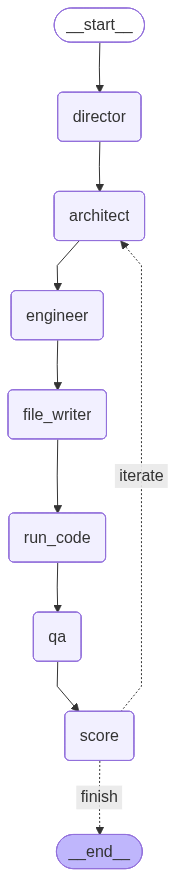

In [0]:
from IPython.display import Image, display
# Render as PNG
display(Image(app.get_graph().draw_mermaid_png()))